In [11]:
import numpy as np
from tokenizers import Tokenizer
from collections import OrderedDict
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0, str(root))

import Project1

In [12]:
dataset = load_dataset("cardiffnlp/tweet_eval", "stance_climate")

In [13]:
# feature representation

class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        vector = np.zeros(len(self))
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

class tfidf(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        self.dataset = dataset['train']
        self.idf = self._compute_idf()

    def _compute_idf(self) -> 'np.array':
        num_documents = len(self.dataset)
        df = np.zeros(len(self.tokenizer.get_vocab()))

        for example in self.dataset:
            unique_token_ids = set(self.tokenizer.encode(example['text']).ids)
            for token_id in unique_token_ids:
                df[token_id] += 1

        idf = np.log((num_documents + 1) / (df + 1)) + 1
        return idf

    def __len__(self) -> int:
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        tf_vector = np.zeros(len(self))
        token_ids = self.tokenizer.encode(x).ids

        for token_id in token_ids:
            tf_vector[token_id] += 1

        if len(token_ids) > 0:
            tf_vector /= len(token_ids)

        tfidf_vector = tf_vector * self.idf
        return tfidf_vector

In [14]:
#tokenizer
vocab_size = 1000
min_frequency = 2
corpus = [text for text in dataset["train"]["text"]]
tokenizer = Project1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
token_indicator_encoder = TokenIndicator(tokenizer)

In [15]:
# cross-validation
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        Project1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["text"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

In [16]:
results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True) 

In [17]:
# classifiers
logistic_model = Project1.loglin.fit(my_cross_validation_sets[0][0]["training"], token_indicator_encoder, save_to=None)



/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [18]:
outcome_space_abortion = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_atheism = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_climate = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_feminist = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])
outcome_space_hillary = Project1.clslib.NamedClasses(['against', 'neutral', 'in favor'])

In [19]:
classifiers = OrderedDict()

In [20]:
token_indicator_encoder = TokenIndicator(tokenizer)
bow_encoder = BagOfWords(tokenizer)
tfidf_encoder = tfidf(tokenizer)

In [21]:
classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"{results_folder}/logistic_indicator-enc/seed-{seed}"
    classifiers['logistic_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, catego

In [22]:
classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp_indicator-enc/seed-{seed}"
    classifiers['mlp_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.068 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0381 | train acc: 0.4894 | val loss: 1.0145 | val acc: 0.4225
Epoch 02 | train loss: 0.8736 | train acc: 0.6796 | val loss: 0.9653 | val acc: 0.4225
Epoch 03 | train loss: 0.7564 | train acc: 0.7218 | val loss: 0.9504 | val acc: 0.4225
Epoch 04 | train loss: 0.6606 | train acc: 0.7746 | val loss: 0.9508 | val acc: 0.4225


/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/richard/Documents/NLP1/Projects/NLP1/Project1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 05 | train loss: 0.5897 | train acc: 0.8345 | val loss: 0.9566 | val acc: 0.4507
Epoch 06 | train loss: 0.5216 | train acc: 0.8838 | val loss: 0.9625 | val acc: 0.4789
Epoch 07 | train loss: 0.4585 | train acc: 0.9190 | val loss: 0.9676 | val acc: 0.5070
Epoch 08 | train loss: 0.3861 | train acc: 0.9577 | val loss: 0.9701 | val acc: 0.5352
Epoch 09 | train loss: 0.3326 | train acc: 0.9613 | val loss: 0.9706 | val acc: 0.5352
Epoch 10 | train loss: 0.2777 | train acc: 0.9613 | val loss: 0.9718 | val acc: 0.5493
Epoch 11 | train loss: 0.2307 | train acc: 0.9683 | val loss: 0.9763 | val acc: 0.5493
Epoch 12 | train loss: 0.1931 | train acc: 0.9683 | val loss: 0.9906 | val acc: 0.5493
Epoch 13 | train loss: 0.1590 | train acc: 0.9718 | val loss: 1.0109 | val acc: 0.5634
Epoch 14 | train loss: 0.1342 | train acc: 0.9789 | val loss: 1.0244 | val acc: 0.5493
Epoch 15 | train loss: 0.1106 | train acc: 0.9859 | val loss: 1.0417 | val acc: 0.5634
Epoch 16 | train loss: 0.0973 | train acc: 

... (4 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0617 | train acc: 0.4930 | val loss: 0.9822 | val acc: 0.5493
Epoch 02 | train loss: 0.9127 | train acc: 0.6338 | val loss: 0.8965 | val acc: 0.5634
Epoch 03 | train loss: 0.7998 | train acc: 0.6937 | val loss: 0.8347 | val acc: 0.5634
Epoch 04 | train loss: 0.7093 | train acc: 0.7606 | val loss: 0.7908 | val acc: 0.5634
Epoch 05 | train loss: 0.6325 | train acc: 0.8556 | val loss: 0.7597 | val acc: 0.5915
Epoch 06 | train loss: 0.5632 | train acc: 0.8838 | val loss: 0.7361 | val acc: 0.6056
Epoch 07 | train loss: 0.4929 | train acc: 0.9225 | val loss: 0.7094 | val acc: 0.7042
Epoch 08 | train loss: 0.4288 | train acc: 0.9401 | val loss: 0.6832 | val acc: 0.7324
Epoch 09 | train loss: 0.3669 | train acc: 0.9472 | val loss: 0.6604 | val acc: 0.7746
Epoch 10 | train loss: 0.3094 | train acc: 0.9542 | val loss: 0.6494 | val acc: 0.7746
Epoch 11 | train loss: 0.2582 | train acc: 0.9613 | val loss: 0.6346 | val acc: 0.7746
Epoch 12 | train loss: 0.2170 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0677 | train acc: 0.3873 | val loss: 0.9697 | val acc: 0.6338
Epoch 02 | train loss: 0.9369 | train acc: 0.7077 | val loss: 0.8822 | val acc: 0.5211
Epoch 03 | train loss: 0.8335 | train acc: 0.7218 | val loss: 0.8124 | val acc: 0.5070
Epoch 04 | train loss: 0.7485 | train acc: 0.7254 | val loss: 0.7600 | val acc: 0.5070
Epoch 05 | train loss: 0.6809 | train acc: 0.7430 | val loss: 0.7200 | val acc: 0.5211
Epoch 06 | train loss: 0.6115 | train acc: 0.8275 | val loss: 0.6868 | val acc: 0.5915
Epoch 07 | train loss: 0.5370 | train acc: 0.8908 | val loss: 0.6574 | val acc: 0.6056
Epoch 08 | train loss: 0.4672 | train acc: 0.9331 | val loss: 0.6337 | val acc: 0.6338
Epoch 09 | train loss: 0.3975 | train acc: 0.9542 | val loss: 0.6162 | val acc: 0.6761
Epoch 10 | train loss: 0.3385 | train acc: 0.9577 | val loss: 0.6066 | val acc: 0.6620
Epoch 11 | train loss: 0.2826 | train acc: 0.9613 | val loss: 0.6018 | val acc: 0.6761
Epoch 12 | train loss: 0.2364 | train acc: 

In [23]:
classifiers['mlp2_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_indicator-enc/seed-{seed}"
    classifiers['mlp2_indicator-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=token_indicator_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.064 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0864 | train acc: 0.4331 | val loss: 1.0612 | val acc: 0.4366
Epoch 02 | train loss: 0.9793 | train acc: 0.5634 | val loss: 1.0079 | val acc: 0.4366
Epoch 03 | train loss: 0.8694 | train acc: 0.5634 | val loss: 0.9738 | val acc: 0.4366
Epoch 04 | train loss: 0.7688 | train acc: 0.5634 | val loss: 0.9754 | val acc: 0.4366
Epoch 05 | train loss: 0.6805 | train acc: 0.5739 | val loss: 0.9750 | val acc: 0.4225
Epoch 06 | train loss: 0.5859 | train acc: 0.7782 | val loss: 0.9727 | val acc: 0.4789
Epoch 07 | train loss: 0.4753 | train acc: 0.9190 | val loss: 1.0040 | val acc: 0.4789
Epoch 08 | train loss: 0.3477 | train acc: 0.9366 | val loss: 1.0401 | val acc: 0.5211
Epoch 09 | train loss: 0.2360 | train acc: 0.9542 | val loss: 1.0534 | val acc: 0.5352
Epoch 10 | train loss: 0.1598 | train acc: 0.9683 | val loss: 1.1496 | val acc: 0.5352
Epoch 11 | train loss: 0.1066 | train acc: 0.9718 | val loss: 1.2243 | val acc: 0.5352
Epoch 12 | train loss: 0.0778 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0669 | train acc: 0.4577 | val loss: 1.0065 | val acc: 0.3239
Epoch 02 | train loss: 0.9500 | train acc: 0.5739 | val loss: 0.8727 | val acc: 0.5352
Epoch 03 | train loss: 0.8295 | train acc: 0.8275 | val loss: 0.7598 | val acc: 0.7042
Epoch 04 | train loss: 0.7356 | train acc: 0.7817 | val loss: 0.7023 | val acc: 0.7465
Epoch 05 | train loss: 0.6592 | train acc: 0.8239 | val loss: 0.6820 | val acc: 0.7465
Epoch 06 | train loss: 0.5481 | train acc: 0.9155 | val loss: 0.6523 | val acc: 0.7183
Epoch 07 | train loss: 0.4367 | train acc: 0.9190 | val loss: 0.6514 | val acc: 0.6338
Epoch 08 | train loss: 0.3196 | train acc: 0.9401 | val loss: 0.6060 | val acc: 0.7042
Epoch 09 | train loss: 0.2189 | train acc: 0.9577 | val loss: 0.6236 | val acc: 0.7042
Epoch 10 | train loss: 0.1495 | train acc: 0.9613 | val loss: 0.6959 | val acc: 0.6479
Epoch 11 | train loss: 0.1072 | train acc: 0.9613 | val loss: 0.7637 | val acc: 0.6479
Epoch 12 | train loss: 0.0783 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0735 | train acc: 0.4401 | val loss: 1.0031 | val acc: 0.5493
Epoch 02 | train loss: 0.9653 | train acc: 0.5352 | val loss: 0.9062 | val acc: 0.5493
Epoch 03 | train loss: 0.8572 | train acc: 0.5352 | val loss: 0.8236 | val acc: 0.5493
Epoch 04 | train loss: 0.7629 | train acc: 0.5387 | val loss: 0.7771 | val acc: 0.5493
Epoch 05 | train loss: 0.6702 | train acc: 0.6655 | val loss: 0.7439 | val acc: 0.6338
Epoch 06 | train loss: 0.5690 | train acc: 0.9085 | val loss: 0.7092 | val acc: 0.7324
Epoch 07 | train loss: 0.4525 | train acc: 0.9296 | val loss: 0.6752 | val acc: 0.7606
Epoch 08 | train loss: 0.3238 | train acc: 0.9507 | val loss: 0.6516 | val acc: 0.7746
Epoch 09 | train loss: 0.2301 | train acc: 0.9542 | val loss: 0.6167 | val acc: 0.7887
Epoch 10 | train loss: 0.1556 | train acc: 0.9613 | val loss: 0.6236 | val acc: 0.8028
Epoch 11 | train loss: 0.1082 | train acc: 0.9718 | val loss: 0.6393 | val acc: 0.8028
Epoch 12 | train loss: 0.0792 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0565 | train acc: 0.4894 | val loss: 0.9909 | val acc: 0.5211
Epoch 02 | train loss: 0.9550 | train acc: 0.5458 | val loss: 0.8934 | val acc: 0.5211
Epoch 03 | train loss: 0.8499 | train acc: 0.5423 | val loss: 0.8085 | val acc: 0.5211
Epoch 04 | train loss: 0.7767 | train acc: 0.5423 | val loss: 0.7529 | val acc: 0.5211
Epoch 05 | train loss: 0.6945 | train acc: 0.5563 | val loss: 0.7020 | val acc: 0.5211
Epoch 06 | train loss: 0.6084 | train acc: 0.8134 | val loss: 0.6680 | val acc: 0.5634
Epoch 07 | train loss: 0.5039 | train acc: 0.9190 | val loss: 0.6435 | val acc: 0.5634
Epoch 08 | train loss: 0.3840 | train acc: 0.9366 | val loss: 0.6320 | val acc: 0.5915
Epoch 09 | train loss: 0.2776 | train acc: 0.9472 | val loss: 0.6274 | val acc: 0.6197
Epoch 10 | train loss: 0.1930 | train acc: 0.9542 | val loss: 0.6564 | val acc: 0.6338
Epoch 11 | train loss: 0.1344 | train acc: 0.9542 | val loss: 0.6982 | val acc: 0.6338
Epoch 12 | train loss: 0.1011 | train acc: 

In [24]:
classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_bow-enc/seed-{seed}"
    classifiers['logistic_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={'max_iter': 100}
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [25]:
classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_bow-enc/seed-{seed}"
    classifiers['mlp_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.063 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0381 | train acc: 0.5176 | val loss: 0.9985 | val acc: 0.5211
Epoch 02 | train loss: 0.8763 | train acc: 0.7007 | val loss: 0.9481 | val acc: 0.4930
Epoch 03 | train loss: 0.7679 | train acc: 0.6796 | val loss: 0.9307 | val acc: 0.5070
Epoch 04 | train loss: 0.6858 | train acc: 0.6690 | val loss: 0.9287 | val acc: 0.4930
Epoch 05 | train loss: 0.6142 | train acc: 0.7465 | val loss: 0.9244 | val acc: 0.5070
Epoch 06 | train loss: 0.5478 | train acc: 0.8451 | val loss: 0.9199 | val acc: 0.5352
Epoch 07 | train loss: 0.4861 | train acc: 0.9190 | val loss: 0.9146 | val acc: 0.5775
Epoch 08 | train loss: 0.4164 | train acc: 0.9577 | val loss: 0.9124 | val acc: 0.6056
Epoch 09 | train loss: 0.3556 | train acc: 0.9577 | val loss: 0.9124 | val acc: 0.6197
Epoch 10 | train loss: 0.2991 | train acc: 0.9683 | val loss: 0.9174 | val acc: 0.6056
Epoch 11 | train loss: 0.2497 | train acc: 0.9683 | val loss: 0.9269 | val acc: 0.6056
Epoch 12 | train loss: 0.2057 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0613 | train acc: 0.4225 | val loss: 0.9443 | val acc: 0.6338
Epoch 02 | train loss: 0.9071 | train acc: 0.6690 | val loss: 0.8408 | val acc: 0.6761
Epoch 03 | train loss: 0.8043 | train acc: 0.7359 | val loss: 0.7734 | val acc: 0.7042
Epoch 04 | train loss: 0.7163 | train acc: 0.8521 | val loss: 0.7362 | val acc: 0.7324
Epoch 05 | train loss: 0.6433 | train acc: 0.8838 | val loss: 0.7027 | val acc: 0.7324
Epoch 06 | train loss: 0.5713 | train acc: 0.9225 | val loss: 0.6796 | val acc: 0.7746
Epoch 07 | train loss: 0.4996 | train acc: 0.9331 | val loss: 0.6643 | val acc: 0.7465
Epoch 08 | train loss: 0.4298 | train acc: 0.9542 | val loss: 0.6590 | val acc: 0.6620
Epoch 09 | train loss: 0.3691 | train acc: 0.9577 | val loss: 0.6530 | val acc: 0.6479
Epoch 10 | train loss: 0.3095 | train acc: 0.9648 | val loss: 0.6352 | val acc: 0.6761
Epoch 11 | train loss: 0.2591 | train acc: 0.9718 | val loss: 0.6314 | val acc: 0.6620
Epoch 12 | train loss: 0.2171 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0682 | train acc: 0.4120 | val loss: 0.9717 | val acc: 0.6338
Epoch 02 | train loss: 0.9163 | train acc: 0.7183 | val loss: 0.8791 | val acc: 0.5915
Epoch 03 | train loss: 0.8005 | train acc: 0.7465 | val loss: 0.8170 | val acc: 0.5915
Epoch 04 | train loss: 0.7165 | train acc: 0.7535 | val loss: 0.7766 | val acc: 0.5915
Epoch 05 | train loss: 0.6450 | train acc: 0.7958 | val loss: 0.7492 | val acc: 0.5915
Epoch 06 | train loss: 0.5674 | train acc: 0.8768 | val loss: 0.7232 | val acc: 0.6620
Epoch 07 | train loss: 0.4998 | train acc: 0.9296 | val loss: 0.7001 | val acc: 0.7183
Epoch 08 | train loss: 0.4349 | train acc: 0.9437 | val loss: 0.6782 | val acc: 0.7465
Epoch 09 | train loss: 0.3727 | train acc: 0.9507 | val loss: 0.6617 | val acc: 0.7465
Epoch 10 | train loss: 0.3155 | train acc: 0.9542 | val loss: 0.6471 | val acc: 0.7465
Epoch 11 | train loss: 0.2688 | train acc: 0.9577 | val loss: 0.6377 | val acc: 0.7465
Epoch 12 | train loss: 0.2257 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0563 | train acc: 0.4648 | val loss: 0.9644 | val acc: 0.4930
Epoch 02 | train loss: 0.9022 | train acc: 0.6232 | val loss: 0.8731 | val acc: 0.5211
Epoch 03 | train loss: 0.8033 | train acc: 0.6162 | val loss: 0.8064 | val acc: 0.5211
Epoch 04 | train loss: 0.7133 | train acc: 0.6725 | val loss: 0.7536 | val acc: 0.5211
Epoch 05 | train loss: 0.6362 | train acc: 0.8099 | val loss: 0.7137 | val acc: 0.5352
Epoch 06 | train loss: 0.5632 | train acc: 0.8803 | val loss: 0.6800 | val acc: 0.6338
Epoch 07 | train loss: 0.4958 | train acc: 0.9155 | val loss: 0.6536 | val acc: 0.6479
Epoch 08 | train loss: 0.4299 | train acc: 0.9366 | val loss: 0.6360 | val acc: 0.6761
Epoch 09 | train loss: 0.3622 | train acc: 0.9472 | val loss: 0.6248 | val acc: 0.6901
Epoch 10 | train loss: 0.3071 | train acc: 0.9577 | val loss: 0.6197 | val acc: 0.6761
Epoch 11 | train loss: 0.2598 | train acc: 0.9577 | val loss: 0.6170 | val acc: 0.6761
Epoch 12 | train loss: 0.2110 | train acc: 

In [26]:
classifiers['mlp2_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_bow-enc/seed-{seed}"
    classifiers['mlp2_bow-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.076 seconds
Dataloader done! Time taken: 0.003 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0967 | train acc: 0.3310 | val loss: 1.0580 | val acc: 0.4085
Epoch 02 | train loss: 0.9680 | train acc: 0.5986 | val loss: 0.9922 | val acc: 0.4366
Epoch 03 | train loss: 0.8384 | train acc: 0.5739 | val loss: 0.9524 | val acc: 0.4366
Epoch 04 | train loss: 0.7213 | train acc: 0.5951 | val loss: 0.9596 | val acc: 0.4366
Epoch 05 | train loss: 0.6213 | train acc: 0.6514 | val loss: 0.9774 | val acc: 0.4507
Epoch 06 | train loss: 0.5197 | train acc: 0.9085 | val loss: 0.9680 | val acc: 0.5915
Epoch 07 | train loss: 0.4030 | train acc: 0.9542 | val loss: 0.9885 | val acc: 0.5775
Epoch 08 | train loss: 0.2859 | train acc: 0.9613 | val loss: 1.0255 | val acc: 0.5775
Epoch 09 | train loss: 0.1928 | train acc: 0.9683 | val loss: 1.0234 | val acc: 0.5915
Epoch 10 | train loss: 0.1292 | train acc: 0.9718 | val loss: 1.0860 | val acc: 0.5775
Epoch 11 | train loss: 0.0889 | train acc: 0.9718 | val loss: 1.1836 | val acc: 0.5915
Epoch 12 | train loss: 0.0656 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1019 | train acc: 0.3099 | val loss: 1.0086 | val acc: 0.6761
Epoch 02 | train loss: 0.9849 | train acc: 0.5317 | val loss: 0.8975 | val acc: 0.6761
Epoch 03 | train loss: 0.8814 | train acc: 0.5493 | val loss: 0.7904 | val acc: 0.6901
Epoch 04 | train loss: 0.7801 | train acc: 0.6479 | val loss: 0.7335 | val acc: 0.7465
Epoch 05 | train loss: 0.7106 | train acc: 0.8345 | val loss: 0.7081 | val acc: 0.7465
Epoch 06 | train loss: 0.6207 | train acc: 0.8768 | val loss: 0.6638 | val acc: 0.7606
Epoch 07 | train loss: 0.5034 | train acc: 0.9085 | val loss: 0.6376 | val acc: 0.7606
Epoch 08 | train loss: 0.3900 | train acc: 0.9261 | val loss: 0.6284 | val acc: 0.6901
Epoch 09 | train loss: 0.2770 | train acc: 0.9296 | val loss: 0.6100 | val acc: 0.7324
Epoch 10 | train loss: 0.1871 | train acc: 0.9507 | val loss: 0.6350 | val acc: 0.7183
Epoch 11 | train loss: 0.1278 | train acc: 0.9613 | val loss: 0.7128 | val acc: 0.6761
Epoch 12 | train loss: 0.0946 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0743 | train acc: 0.3697 | val loss: 1.0011 | val acc: 0.6197
Epoch 02 | train loss: 0.9506 | train acc: 0.6373 | val loss: 0.8965 | val acc: 0.5493
Epoch 03 | train loss: 0.8423 | train acc: 0.5493 | val loss: 0.8110 | val acc: 0.5493
Epoch 04 | train loss: 0.7459 | train acc: 0.5739 | val loss: 0.7735 | val acc: 0.5493
Epoch 05 | train loss: 0.6722 | train acc: 0.6761 | val loss: 0.7509 | val acc: 0.6197
Epoch 06 | train loss: 0.5815 | train acc: 0.8768 | val loss: 0.7206 | val acc: 0.7606
Epoch 07 | train loss: 0.4874 | train acc: 0.9190 | val loss: 0.6814 | val acc: 0.7746
Epoch 08 | train loss: 0.3632 | train acc: 0.9401 | val loss: 0.6428 | val acc: 0.7746
Epoch 09 | train loss: 0.2656 | train acc: 0.9507 | val loss: 0.6080 | val acc: 0.7887
Epoch 10 | train loss: 0.1824 | train acc: 0.9577 | val loss: 0.6117 | val acc: 0.7887
Epoch 11 | train loss: 0.1239 | train acc: 0.9648 | val loss: 0.6156 | val acc: 0.8169
Epoch 12 | train loss: 0.0844 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0996 | train acc: 0.3239 | val loss: 1.0310 | val acc: 0.5211
Epoch 02 | train loss: 0.9811 | train acc: 0.5458 | val loss: 0.9167 | val acc: 0.5211
Epoch 03 | train loss: 0.8648 | train acc: 0.5423 | val loss: 0.8134 | val acc: 0.5211
Epoch 04 | train loss: 0.7634 | train acc: 0.5599 | val loss: 0.7343 | val acc: 0.5352
Epoch 05 | train loss: 0.6667 | train acc: 0.7465 | val loss: 0.6783 | val acc: 0.6338
Epoch 06 | train loss: 0.5597 | train acc: 0.8803 | val loss: 0.6478 | val acc: 0.6761
Epoch 07 | train loss: 0.4332 | train acc: 0.9049 | val loss: 0.6325 | val acc: 0.7042
Epoch 08 | train loss: 0.3083 | train acc: 0.9401 | val loss: 0.6250 | val acc: 0.6338
Epoch 09 | train loss: 0.2221 | train acc: 0.9472 | val loss: 0.6414 | val acc: 0.6338
Epoch 10 | train loss: 0.1569 | train acc: 0.9613 | val loss: 0.6760 | val acc: 0.6620
Epoch 11 | train loss: 0.1121 | train acc: 0.9577 | val loss: 0.7152 | val acc: 0.6620
Epoch 12 | train loss: 0.0849 | train acc: 

In [27]:
classifiers['logistic_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/logistic_tfidf-enc/seed-{seed}"
    classifiers['logistic_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/richard/envs/nlp1-2026/lib/python3.14/site-packages/sklear

In [28]:
classifiers['mlp_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/mlp_tfidf-enc/seed-{seed}"
    classifiers['mlp_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=tfidf(tokenizer),
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.066 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0824 | train acc: 0.4824 | val loss: 1.0763 | val acc: 0.4225
Epoch 02 | train loss: 1.0542 | train acc: 0.7782 | val loss: 1.0598 | val acc: 0.4789
Epoch 03 | train loss: 1.0260 | train acc: 0.7570 | val loss: 1.0408 | val acc: 0.4648
Epoch 04 | train loss: 0.9921 | train acc: 0.6937 | val loss: 1.0198 | val acc: 0.4366
Epoch 05 | train loss: 0.9522 | train acc: 0.6268 | val loss: 0.9982 | val acc: 0.4366
Epoch 06 | train loss: 0.9096 | train acc: 0.6127 | val loss: 0.9770 | val acc: 0.4366
Epoch 07 | train loss: 0.8639 | train acc: 0.5986 | val loss: 0.9578 | val acc: 0.4366
Epoch 08 | train loss: 0.8178 | train acc: 0.6092 | val loss: 0.9409 | val acc: 0.4366
Epoch 09 | train loss: 0.7750 | train acc: 0.6268 | val loss: 0.9290 | val acc: 0.4366
Epoch 10 | train loss: 0.7320 | train acc: 0.6444 | val loss: 0.9209 | val acc: 0.4507
Epoch 11 | train loss: 0.6907 | train acc: 0.6761 | val loss: 0.9169 | val acc: 0.4507
Epoch 12 | train loss: 0.6540 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0639 | train acc: 0.4859 | val loss: 1.0522 | val acc: 0.3380
Epoch 02 | train loss: 1.0376 | train acc: 0.6408 | val loss: 1.0275 | val acc: 0.3521
Epoch 03 | train loss: 1.0091 | train acc: 0.7500 | val loss: 0.9978 | val acc: 0.4366
Epoch 04 | train loss: 0.9740 | train acc: 0.7817 | val loss: 0.9646 | val acc: 0.4648
Epoch 05 | train loss: 0.9350 | train acc: 0.8380 | val loss: 0.9296 | val acc: 0.5070
Epoch 06 | train loss: 0.8952 | train acc: 0.8697 | val loss: 0.8920 | val acc: 0.5775
Epoch 07 | train loss: 0.8536 | train acc: 0.9085 | val loss: 0.8564 | val acc: 0.5915
Epoch 08 | train loss: 0.8130 | train acc: 0.9261 | val loss: 0.8218 | val acc: 0.6620
Epoch 09 | train loss: 0.7718 | train acc: 0.9261 | val loss: 0.7918 | val acc: 0.7324
Epoch 10 | train loss: 0.7359 | train acc: 0.9401 | val loss: 0.7658 | val acc: 0.7465
Epoch 11 | train loss: 0.6997 | train acc: 0.9331 | val loss: 0.7413 | val acc: 0.7746
Epoch 12 | train loss: 0.6662 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0507 | train acc: 0.5352 | val loss: 1.0383 | val acc: 0.5775
Epoch 02 | train loss: 1.0268 | train acc: 0.6268 | val loss: 1.0178 | val acc: 0.5634
Epoch 03 | train loss: 1.0001 | train acc: 0.6479 | val loss: 0.9937 | val acc: 0.5634
Epoch 04 | train loss: 0.9702 | train acc: 0.6725 | val loss: 0.9656 | val acc: 0.5634
Epoch 05 | train loss: 0.9349 | train acc: 0.6690 | val loss: 0.9344 | val acc: 0.5493
Epoch 06 | train loss: 0.8955 | train acc: 0.6761 | val loss: 0.9019 | val acc: 0.5493
Epoch 07 | train loss: 0.8561 | train acc: 0.6725 | val loss: 0.8695 | val acc: 0.5634
Epoch 08 | train loss: 0.8132 | train acc: 0.6972 | val loss: 0.8383 | val acc: 0.5634
Epoch 09 | train loss: 0.7727 | train acc: 0.7148 | val loss: 0.8107 | val acc: 0.5634
Epoch 10 | train loss: 0.7328 | train acc: 0.7570 | val loss: 0.7863 | val acc: 0.5634
Epoch 11 | train loss: 0.6928 | train acc: 0.7817 | val loss: 0.7641 | val acc: 0.5915
Epoch 12 | train loss: 0.6561 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.1007 | train acc: 0.3134 | val loss: 1.0840 | val acc: 0.5493
Epoch 02 | train loss: 1.0709 | train acc: 0.6972 | val loss: 1.0570 | val acc: 0.5352
Epoch 03 | train loss: 1.0397 | train acc: 0.7711 | val loss: 1.0251 | val acc: 0.5493
Epoch 04 | train loss: 1.0041 | train acc: 0.6937 | val loss: 0.9883 | val acc: 0.5352
Epoch 05 | train loss: 0.9632 | train acc: 0.6197 | val loss: 0.9491 | val acc: 0.5352
Epoch 06 | train loss: 0.9199 | train acc: 0.5915 | val loss: 0.9095 | val acc: 0.5352
Epoch 07 | train loss: 0.8753 | train acc: 0.5951 | val loss: 0.8714 | val acc: 0.5352
Epoch 08 | train loss: 0.8306 | train acc: 0.5915 | val loss: 0.8368 | val acc: 0.5352
Epoch 09 | train loss: 0.7902 | train acc: 0.5880 | val loss: 0.8063 | val acc: 0.5352
Epoch 10 | train loss: 0.7512 | train acc: 0.6232 | val loss: 0.7788 | val acc: 0.5493
Epoch 11 | train loss: 0.7125 | train acc: 0.6655 | val loss: 0.7544 | val acc: 0.5352
Epoch 12 | train loss: 0.6758 | train acc: 

In [29]:
classifiers['mlp2_tfidf-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"{results_folder}/mlp2_tfidf-enc/seed-{seed}"
    classifiers['mlp2_tfidf-enc'].append(
        Project1.experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=outcome_space_climate,
            encoder=bow_encoder,
            model_option='mlp2', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-3, 
                'weight_decay': 1e-4, 
                'num_epochs': 100,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 0.066 seconds
Dataloader done! Time taken: 0.002 seconds
Training...


  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0929 | train acc: 0.3662 | val loss: 1.0516 | val acc: 0.4366
Epoch 02 | train loss: 0.9635 | train acc: 0.5669 | val loss: 0.9887 | val acc: 0.4366
Epoch 03 | train loss: 0.8380 | train acc: 0.5634 | val loss: 0.9575 | val acc: 0.4366
Epoch 04 | train loss: 0.7315 | train acc: 0.5634 | val loss: 0.9631 | val acc: 0.4366
Epoch 05 | train loss: 0.6400 | train acc: 0.6444 | val loss: 0.9623 | val acc: 0.4930
Epoch 06 | train loss: 0.5508 | train acc: 0.8908 | val loss: 0.9688 | val acc: 0.6056
Epoch 07 | train loss: 0.4261 | train acc: 0.9472 | val loss: 1.0097 | val acc: 0.5352
Epoch 08 | train loss: 0.3162 | train acc: 0.9472 | val loss: 1.0026 | val acc: 0.6338
Epoch 09 | train loss: 0.2140 | train acc: 0.9648 | val loss: 1.0088 | val acc: 0.5915
Epoch 10 | train loss: 0.1393 | train acc: 0.9718 | val loss: 1.0778 | val acc: 0.6197
Epoch 11 | train loss: 0.0920 | train acc: 0.9754 | val loss: 1.1606 | val acc: 0.6338
Epoch 12 | train loss: 0.0646 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0999 | train acc: 0.3063 | val loss: 1.0300 | val acc: 0.4930
Epoch 02 | train loss: 0.9840 | train acc: 0.7113 | val loss: 0.9102 | val acc: 0.6901
Epoch 03 | train loss: 0.8767 | train acc: 0.6021 | val loss: 0.7869 | val acc: 0.6761
Epoch 04 | train loss: 0.7859 | train acc: 0.5176 | val loss: 0.7227 | val acc: 0.6901
Epoch 05 | train loss: 0.7011 | train acc: 0.7042 | val loss: 0.7300 | val acc: 0.6479
Epoch 06 | train loss: 0.6199 | train acc: 0.9120 | val loss: 0.7092 | val acc: 0.6620
Epoch 07 | train loss: 0.5075 | train acc: 0.9120 | val loss: 0.6507 | val acc: 0.7606
Epoch 08 | train loss: 0.3875 | train acc: 0.9190 | val loss: 0.6420 | val acc: 0.7324
Epoch 09 | train loss: 0.2778 | train acc: 0.9507 | val loss: 0.6769 | val acc: 0.6620
Epoch 10 | train loss: 0.1906 | train acc: 0.9542 | val loss: 0.6817 | val acc: 0.7465
Epoch 11 | train loss: 0.1302 | train acc: 0.9542 | val loss: 0.7542 | val acc: 0.7042
Epoch 12 | train loss: 0.0941 | train acc: 

... (2 outputs left out)

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0816 | train acc: 0.3732 | val loss: 0.9932 | val acc: 0.5493
Epoch 02 | train loss: 0.9369 | train acc: 0.5493 | val loss: 0.8764 | val acc: 0.5493
Epoch 03 | train loss: 0.8153 | train acc: 0.5387 | val loss: 0.8010 | val acc: 0.5493
Epoch 04 | train loss: 0.7224 | train acc: 0.6338 | val loss: 0.7695 | val acc: 0.6056
Epoch 05 | train loss: 0.6389 | train acc: 0.8451 | val loss: 0.7446 | val acc: 0.6620
Epoch 06 | train loss: 0.5334 | train acc: 0.8873 | val loss: 0.7149 | val acc: 0.7042
Epoch 07 | train loss: 0.4125 | train acc: 0.9085 | val loss: 0.6689 | val acc: 0.7183
Epoch 08 | train loss: 0.3017 | train acc: 0.9366 | val loss: 0.6574 | val acc: 0.7606
Epoch 09 | train loss: 0.2165 | train acc: 0.9507 | val loss: 0.6538 | val acc: 0.7746
Epoch 10 | train loss: 0.1498 | train acc: 0.9542 | val loss: 0.6559 | val acc: 0.7746
Epoch 11 | train loss: 0.1069 | train acc: 0.9577 | val loss: 0.6854 | val acc: 0.7887
Epoch 12 | train loss: 0.0823 | train acc: 

  0%|          | 0/100 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.0502 | train acc: 0.4331 | val loss: 0.9769 | val acc: 0.6056
Epoch 02 | train loss: 0.9358 | train acc: 0.6761 | val loss: 0.8618 | val acc: 0.5070
Epoch 03 | train loss: 0.8208 | train acc: 0.5775 | val loss: 0.7650 | val acc: 0.5211
Epoch 04 | train loss: 0.7344 | train acc: 0.5599 | val loss: 0.7078 | val acc: 0.5211
Epoch 05 | train loss: 0.6441 | train acc: 0.7254 | val loss: 0.6621 | val acc: 0.6056
Epoch 06 | train loss: 0.5426 | train acc: 0.8838 | val loss: 0.6350 | val acc: 0.6338
Epoch 07 | train loss: 0.4220 | train acc: 0.9085 | val loss: 0.6215 | val acc: 0.6338
Epoch 08 | train loss: 0.3042 | train acc: 0.9190 | val loss: 0.6276 | val acc: 0.6338
Epoch 09 | train loss: 0.2141 | train acc: 0.9401 | val loss: 0.6456 | val acc: 0.6620
Epoch 10 | train loss: 0.1513 | train acc: 0.9472 | val loss: 0.6823 | val acc: 0.6901
Epoch 11 | train loss: 0.1097 | train acc: 0.9542 | val loss: 0.7190 | val acc: 0.6761
Epoch 12 | train loss: 0.0862 | train acc: 

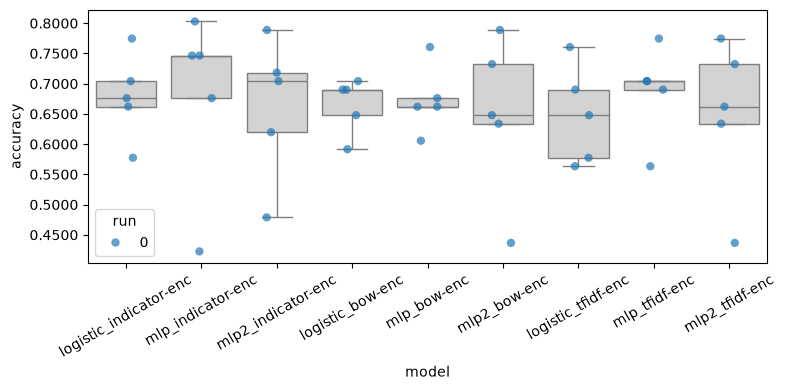

In [30]:
Project1.analysis.plot_box_and_points(Project1.analysis.make_data_frame(classifiers))